OBJETIVO

Sua missão é avaliar os dados e responder a 10 perguntas levantadas pela equipe de
marketing, que estão listadas abaixo:

In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [36]:
#importando dataframe

df= pd.read_csv("vendas_supermercado_com_cliente.csv")

In [41]:
# checando qtde de linhas e colunas do df

df.shape

# 20075 linhas (contando com a linha que consta os nomes das colunas) e 9 colunas

(20075, 9)

In [71]:
#lendo as primeiras 15 linhas do df

df.head(15)

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda
0,2023-01-01,Maçãs,Alimentos Frescos,16.46,10,0.0,164.60,49,2715.61
1,2023-01-01,Bananas,Alimentos Frescos,2.39,4,0.0,9.56,29,2280.15
2,2023-01-01,Laranjas,Alimentos Frescos,8.38,5,0.0,41.90,67,4419.56
3,2023-01-01,Tomates,Alimentos Frescos,2.03,15,0.0,30.45,29,3809.17
4,2023-01-01,Alface,Alimentos Frescos,37.14,14,0.0,519.96,24,1013.42
5,2023-01-01,Cenouras,Alimentos Frescos,17.52,4,0.0,70.08,37,4959.66
6,2023-01-01,Frango,Alimentos Frescos,38.17,3,0.0,114.51,63,2033.87
7,2023-01-01,Carne bovina,Alimentos Frescos,22.07,16,0.0,353.12,32,2682.55
8,2023-01-01,Carne suína,Alimentos Frescos,17.66,9,0.0,158.94,39,1854.33
9,2023-01-01,Salmão,Alimentos Frescos,6.66,2,0.0,13.32,67,1686.49


In [72]:
#lendo as 15 ultimas linhas do df

df.tail(15)

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda
20060,2023-12-31,Papel higiênico,Produtos de Higiene Pessoal,9.81,11,0.18,88.4862,35,4239.52
20061,2023-12-31,Sorvetes,Congelados,5.44,7,0.23,29.3216,35,1416.45
20062,2023-12-31,Pizzas congeladas,Congelados,2.35,7,0.27,12.0085,20,1079.86
20063,2023-12-31,Vegetais congelados,Congelados,48.79,1,0.12,42.9352,60,1742.69
20064,2023-12-31,Pratos prontos congelados,Congelados,46.23,3,0.17,115.1127,50,1526.18
20065,2023-12-31,Frango empanado,Congelados,4.11,16,0.15,55.8960,22,4272.07
20066,2023-12-31,Ração para cães,Pet Shop,45.21,8,0.16,303.8112,31,4249.12
20067,2023-12-31,Ração para gatos,Pet Shop,31.53,14,0.26,326.6508,20,2676.65
20068,2023-12-31,Petiscos,Pet Shop,37.59,14,0.22,410.4828,74,3827.82
20069,2023-12-31,Brinquedos para pets,Pet Shop,10.58,18,0.13,165.6828,56,1241.06


In [73]:
# checando informações gerais sobre o df
# qtde de nulos, tipos de dados, uso de memória

df.info()

# >> não apresentou linhas com dados nulos, pois todas as colunas apresentam as 20075 linhas não nulas


<class 'pandas.DataFrame'>
RangeIndex: 20075 entries, 0 to 20074
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Data         20075 non-null  str    
 1   Produto      20075 non-null  str    
 2   Categoria    20075 non-null  str    
 3   Preço        20075 non-null  float64
 4   Quantidade   20075 non-null  int64  
 5   Desconto     20075 non-null  float64
 6   Total_Venda  20075 non-null  float64
 7   Idade        20075 non-null  int64  
 8   Renda        20075 non-null  float64
dtypes: float64(4), int64(2), str(3)
memory usage: 1.4 MB


In [ ]:
# aprofundando a checagem de dados nulos

df.isnull().sum()

# >> reforçado que as colunas não apresentam dados nulos

Data           0
Produto        0
Categoria      0
Preço          0
Quantidade     0
Desconto       0
Total_Venda    0
Idade          0
Renda          0
dtype: int64

In [121]:
# checando descritivamente todas as colunas do df (numéricas e categóricas) 

df.describe(include="all").round(1)

# count - todas as 9 colunas apresentam todas as 20075 linhas estão preenchidas, então não possui 
# dados nulos ou ausentes

# unique - qtde de  valores únicos em cada um das colunas. Na coluna "Data", por exemplo, consta que o DF possui 365
# registros únicos, ou seja, 1 ano inteiro de registros.

# top - apresenta valor frequente em cada coluna (moda)

# freq - apresente qtas vezes um dado se repete

# >> a data de '2023-01-01' aparece 55 vezes, sendo o produto "Maçãs" apresentando 365 vezes, possivelmente 
# aparecendo nos registros diariamente e "Alimentos Frescos" aparece 5475 vezes, representa uma parte grande do 
# volume de dados num todo

# mean - média de cada coluna numérica, chamando a atenção para a média de  "Desconto" zerada (grande parte das 
# vendas sem desconto)

# std - desvio padrão(dispersão) dos dados em relação à média

# min / max - menor e maior valor, respectivamente, em cada coluna

# >> variação do 'Preço' (1 a 50) representa uma dispersão significativa (desvio padrão de 14), "Quantidade"
# com variação menor (1 a 19 - desvio padrão de 5,5), "Desconto" com variação baixíssima e desvio quase nulo(0,1) e 
# "Total_Vendas" com dispersão gigantesca(0,9 a 949 com desvio padrão alto 207,8)

# 25%, 50%, 75% - quartis de cada coluna

# >> checando os quartis, a mediana (50%) é próxima da média, representando pouquíssima variação entre o "Preço"
# dos produtos. Consta certo equilíbrio entre a "Quantidade" de protudo (5 - 25%, 10 - 50% e 15 - 75%). A mediana 
# (50%) do "Total_Vendas" é de 186,3, menor que a média (245,9), ou seja, a maioria das vendas faturam baixo
# com algumas de valores elevados, que puxam a média para cima.

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda
count,20075,20075,20075,20075.0,20075.0,20075.0,20075.0,20075.0,20075.0
unique,365,55,9,NaN,NaN,NaN,NaN,NaN,NaN
top,2023-01-01,Maçãs,Alimentos Frescos,NaN,NaN,NaN,NaN,NaN,NaN
freq,55,365,5475,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,25.6,10.0,0.0,245.9,46.0,2999.0
std,NaN,NaN,NaN,14.1,5.5,0.1,207.8,16.5,1159.7
min,NaN,NaN,NaN,1.0,1.0,0.0,0.9,18.0,1000.4
25%,NaN,NaN,NaN,13.3,5.0,0.0,75.6,32.0,1993.6
50%,NaN,NaN,NaN,25.7,10.0,0.0,186.3,46.0,2998.8
75%,NaN,NaN,NaN,37.8,15.0,0.0,370.0,60.0,4007.7


<Axes: xlabel='Total_Venda'>

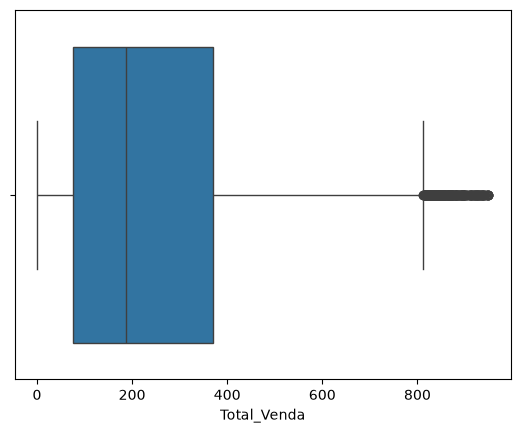

In [122]:
# gráfico para demonstração dos quartis da coluna "Total_Venda", para reafirmar análise descrita no 
# comando anteriormente

sns.boxplot(x=df['Total_Venda'])

In [119]:
# checando duplicidade de linhas no DF

df.duplicated()

# >> análise retorna resposta em booleano
# "False" >>  não detectou linhas duplicadas

0        False
1        False
2        False
3        False
4        False
         ...  
20070    False
20071    False
20072    False
20073    False
20074    False
Length: 20075, dtype: bool

In [113]:
#checando duplicidade de linhas nos DF

df.duplicated().sum()

# >> '0' > não apresenta dados duplicados

np.int64(0)

In [117]:
# demonstra as linhas duplicadas

df[df.duplicated()]

# >> como não tem linhas duplicadas, retornou vazio, como esperado!

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda


In [124]:
# demonstra as linhas NÃO duplicadas

df[~df.duplicated()]

#>> retornou todas as 20075 linhas do DF, como esperado!

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda
0,2023-01-01,Maçãs,Alimentos Frescos,16.46,10,0.00,164.6000,49,2715.61
1,2023-01-01,Bananas,Alimentos Frescos,2.39,4,0.00,9.5600,29,2280.15
2,2023-01-01,Laranjas,Alimentos Frescos,8.38,5,0.00,41.9000,67,4419.56
3,2023-01-01,Tomates,Alimentos Frescos,2.03,15,0.00,30.4500,29,3809.17
4,2023-01-01,Alface,Alimentos Frescos,37.14,14,0.00,519.9600,24,1013.42
...,...,...,...,...,...,...,...,...,...
20070,2023-12-31,Produtos de higiene para pets,Pet Shop,26.62,15,0.21,315.4470,39,2475.82
20071,2023-12-31,Panelas,Utilidades Domésticas,33.00,19,0.15,532.9500,25,4766.49
20072,2023-12-31,Talheres,Utilidades Domésticas,27.60,12,0.29,235.1520,65,3367.68
20073,2023-12-31,Copos,Utilidades Domésticas,15.35,13,0.25,149.6625,42,3823.50


1. Quais foram as categorias produtos mais vendidos e em quais meses eles tiveram o
maior pico de vendas?


In [11]:
# analisando categorias mais vendidas

df.groupby('Categoria')[['Quantidade','Total_Venda']].agg(['count', 'mean','std']).sort_values(by=('Quantidade', 'count'), ascending=False)

# há grande diferença na quantidade de produtos vendidos, onde 'Alimentos Frescos' vendeu 2,5X / 60% mais 
# que o Produtos de Mercearia, a 2º maior categoria em vendas

# entre as demais categorias, não há grandes discrepâncias

Quantidade                      Total_Venda  \
                                 count       mean       std       count   
Categoria                                                                 
Alimentos Frescos                 5475  10.000913  5.518114        5475   
Produtos de Mercearia             2190   9.980365  5.521922        2190   
Bebidas                           1825   9.975890  5.346489        1825   
Laticínios e Ovos                 1825  10.192877  5.546163        1825   
Congelados                        1825   9.890959  5.501560        1825   
Pet Shop                          1825   9.907397  5.559948        1825   
Produtos de Higiene Pessoal       1825  10.067945  5.454837        1825   
Produtos de Limpeza               1825  10.108493  5.448750        1825   
Utilidades Domésticas             1460   9.952055  5.420030        1460   

                                                     
                                   mean         std  
Categoria                                            
Alimentos Frescos            249.371590  211.847617  
Produtos de Mercearia        241.850980  203.741433  
Bebidas                      248.983103  207.971535  
Laticínios e Ovos            252.033135  207.278835  
Congelados                   240.942539  206.162438  
Pet Shop                     241.277569  207.314851  
Produtos de Higiene Pessoal  241.117524  205.590901  
Produtos de Limpeza          245.230606  207.969054  
Utilidades Domésticas        246.248340  203.762444

In [12]:
# Meses que tiveram as maiores vendas de cada categoria

df['Mes']=pd.to_datetime(df['Data']).dt.to_period('M') 
#pandas.to_datetime ( arg , errors = 'raise' , dayfirst = False , yearfirst = False , utc = False , 
#format = None , exact = <no_default> , unit = None , origin = ' unix' , cache = True )
#Converter argumento para data e hora.
#Esta função converte um valor escalar, semelhante a um array Series ou DataFrame semelhante a um 
#dicionário em um objeto datetime do pandas.

#DataFrame.to_period ( freq = None , axis = 0 , copy = <no_default> )​
#Converter DataFrame de DatetimeIndex para PeriodIndex.
#Converta um DataFrame de DatetimeIndex para PeriodIndex com a frequência desejada 
#(inferida a partir do índice, caso não seja especificado). Qualquer índice das colunas pode ser 
#convertido, dependendo do argumento do eixo.

Pico_Vendas=(df.groupby(['Categoria', 'Mes'])['Total_Venda']
            .sum()
            .reset_index()
            .sort_values(by='Total_Venda', ascending=False)
            .drop_duplicates(subset=['Categoria'])
            )

#DataFrame.drop_duplicates ( subset = None , * , keep = ' first ' , inplace = False , 
#ignore_index = False )
#Retorna um DataFrame com as linhas duplicadas removidas.
#Considerar certas colunas é opcional. Os índices, incluindo os índices temporais, são ignorados.

Pico_Vendas

# análise dos meses


,Categoria,Mes,Total_Venda
2,Alimentos Frescos,2023-03,129103.4500
92,Produtos de Mercearia,2023-09,48192.2900
12,Bebidas,2023-01,47415.7100
45,Laticínios e Ovos,2023-10,43440.8032
78,Produtos de Limpeza,2023-07,42358.7500
66,Produtos de Higiene Pessoal,2023-07,42213.3500
48,Pet Shop,2023-01,40577.2900
33,Congelados,2023-10,40418.3384
102,Utilidades Domésticas,2023-07,36674.8100


2. Qual a média de vendas diárias por categoria de produto?


3. Quais produtos apresentam a maior sazonalidade nas vendas (ex.: frutas e vegetais,
sorvetes)

4. Quais as faixas etárias contribuíram mais para as vendas totais? Para responder essa
pergunta, crie uma coluna com a faixa etária, considerando: entre 18 e 35 (jovem), entre
36 e 59 (adulto) e acima de 60 anos (idoso).


5. Qual é a relação entre a idade dos clientes e a categoria de produto mais vendida para
cada?

6. Qual a distribuição das vendas ao longo dos dias da semana?


7. Como as vendas mensais se comparam antes e durante a Black Friday?


8. Qual é o ticket médio (valor médio das vendas) por faixa etária e como ele varia entre
diferentes categorias de produto?


9. Comparando a semana da “Black Friday” com a do Natal, qual semana a empresa teve
melhores desempenhos em relação à média de vendas?


10.Qual foi o impacto das promoções (descontos aplicados) nas vendas? Quais produtos
tiveram o maior aumento nas vendas durante as promoções?